# The Particle Filter (PF)

Course: Recursive State Estimation for Dynamic Systems (SoSe 2026)

Institute: Geodätisches Institut Hannover

Team Members :

1. Arjun Mohandas( Matriculation Nummer:10081891)

2. Aswin Sam(Matriculation Nummer:10082498)

3. Edvin Tony Thampy(Matriculation Nummer:10082986)

This notebook implements the Particle Filter (PF) for estimating the 3D position and velocity of a robot from noisy total-station observations.The unconstrained PF version is implemented and documented.

The implementation follows the notation used in the lecture and exercise sessions.

## Use Of AI

ChatGPT was used for coding review, debugging assistance and researching information.It was mainly used to summarise topics and informations and document them into latex code including equations which were too lengthy and time consuming too write.It was used to understand and minimize code implementations and document information, handle data, plot graphs and diagrams with ease. It was mainly used to check for errors in code and evaluate diagrams to understand their behaviour.The implementations differed from filter to filter.Eventhough AI was used all implementation decisions and final results were verified by us.

## AIM

The Particle Filter is a recursive Bayesian state estimation algorithm designed for nonlinear and non-Gaussian dynamic systems. Unlike the Kalman Filter family, which represents the posterior probability distribution using a Gaussian approximation, the Particle Filter estimates the posterior distribution using a finite set of weighted random samples called **particles**.

The objective of the Particle Filter is to recursively estimate the posterior probability density function

$$
p\!\left(
X^{(k)}
\mid
z^{(1:k)}
\right),
$$

where

- $X^{(k)}$ denotes the system state at epoch $k$,
- $z^{(1:k)}$ denotes all measurements collected from epoch $1$ to $k$.

Instead of assuming that the posterior distribution is Gaussian, the Particle Filter approximates the complete probability distribution using

$$
\boxed{
p\!\left(
X^{(k)}
\mid
z^{(1:k)}
\right)
\approx
\sum_{i=1}^{N_p}
w^{(k,i)}
\,
\delta
\!\left(
X^{(k)}
-
X^{(k,i)}
\right)
}
$$

where

- $X^{(k,i)}$ is the $i^{\mathrm{th}}$ particle at epoch $k$,
- $w^{(k,i)}$ is the normalized importance weight of the $i^{\mathrm{th}}$ particle,
- $N_p$ is the total number of particles,
- $\delta(\cdot)$ is the Dirac delta function.

# PROCEDURE

## State and Measurement Models

The state vector is

$$
X^{(k)}
=
\begin{bmatrix}
X^{(k)}\\
Y^{(k)}\\
Z^{(k)}\\
V_X^{(k)}\\
V_Y^{(k)}\\
V_Z^{(k)}
\end{bmatrix}.
$$

The nonlinear dynamic system model is

$$
X^{(k)}
=
\Phi
X^{(k-1)}
+
w^{(k-1)},
$$

where

$$
w^{(k-1)}
\sim
\mathcal{N}
\left(
0,
Q_{ww}
\right).
$$

The nonlinear observation model is

$$
l^{(k)}
=
h
\left(
X^{(k)}
\right)
+
v^{(k)},
$$

where

$$
l^{(k)}
=
\begin{bmatrix}
H^{(k)}\\
V^{(k)}\\
D^{(k)}
\end{bmatrix}
$$

contains

- Horizontal angle,
- Vertical angle,
- Distance.

The measurement noise is assumed to follow a Gaussian distribution,

$$
v^{(k)}
\sim
\mathcal{N}
\left(
0,
Q_{HVD}^{(k)}
\right).
$$


# PRE-PROCESSING

## Imports and Loading given datafiles

In [109]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# Read observation and ground truth data
obsrv = pd.read_csv("Data/polar0011_slower_0.csv")
gtrue = pd.read_csv("Data/tracker0011_slower_0.csv")

In [110]:
#finding step length dt....

obsrv["time"] = pd.to_datetime(obsrv["Time [HH:MM:SS]"],format="%H:%M:%S.%f") # convert to timestamp 
time_inseconds=(obsrv["time"]-obsrv["time"].iloc[0]) # subtract the column from first timestap to get time in seconds
time_inseconds = time_inseconds.dt.total_seconds()# .dt.total_seconds to get seconds
time_inseconds= time_inseconds.values# convert to np arrays
dt= np.mean(np.diff(time_inseconds)) #Take mean of differences and round it.
dt=round(dt,3)

In [111]:
#Conversion of observations from polar coordinates to cartesian coordinates:
obsrv["H_radian"] = np.deg2rad(obsrv["H [deg]"]) #degree to radian conversion
obsrv["V_radian"]= np.deg2rad(obsrv["V [deg]"])
obsrv["D_m"]= obsrv["D [mm]"] / 1000  #mm to m conversion


X_obsrv = obsrv["D_m"]*np.sin(obsrv["V_radian"])*np.cos(obsrv["H_radian"] )

Y_obsrv = obsrv["D_m"]*np.sin(obsrv["V_radian"])*np.sin(obsrv["H_radian"] )

Z_obsrv = obsrv["D_m"]*np.cos(obsrv["V_radian"])

obsrv["X_obsrv_cart"] = X_obsrv
obsrv["Y_obsrv_cart"] = Y_obsrv
obsrv["Z_obsrv_cart"] = Z_obsrv

X_gtrue = gtrue["X [m]"].values #converting pandas to numpy
Y_gtrue = gtrue["Y [m]"].values
Z_gtrue = gtrue["Z [m]"].values

In [112]:
#system matrices.....

#step length
dt=0.01 

#state_matrix

X0 = obsrv["X_obsrv_cart"].iloc[0]
Y0 = obsrv["Y_obsrv_cart"].iloc[0]
Z0 = obsrv["Z_obsrv_cart"].iloc[0]

X_k= np.array([X0,Y0,Z0,0,0,0])  # velocities are unknown initially

#Transition matrix
#The time step dt is use to build the transition matrix.
Phi_k = np.array([
    [1,0,0,dt,0,0],
    [0,1,0,0,dt,0],
    [0,0,1,0,0,dt],
    [0,0,0,1,0,0],
    [0,0,0,0,1,0],
    [0,0,0,0,0,1]])

sigma_a=2.5

#Then derive Q_ww usimg sigma_a:
Q_ww = sigma_a**2 * np.array([
    [dt**4/4,0,0,dt**3/2,0,0],
    [0,dt**4/4,0,0,dt**3/2,0],
    [0,0,dt**4/4,0,0,dt**3/2],
    [dt**3/2,0,0,dt**2,0,0],
    [0,dt**3/2,0,0,dt**2,0],
    [0,0,dt**3/2,0,0,dt**2]])


In [113]:
#Jacobian Function
#we should convert polar to cartesian using jacobian.
def observation_jacobian(H_radian, V_radian, D_m):
    return np.array([[-D_m * np.sin(V_radian) * np.sin(H_radian),
            D_m * np.cos(V_radian) * np.cos(H_radian),
            np.sin(V_radian) * np.cos(H_radian)],
            [D_m * np.sin(V_radian) * np.cos(H_radian),
            D_m * np.cos(V_radian) * np.sin(H_radian),
            np.sin(V_radian) * np.sin(H_radian)],
            [0,-D_m * np.sin(V_radian),np.cos(V_radian)]])

#Initial or State covariance matrix,Q_xx

sigma_H = np.deg2rad(0.0014)#given in task description
sigma_V = np.deg2rad(0.0014)#given in task description
D_0 = obsrv["D_m"].iloc[0] # Distance for zeroth measurement
sigma_D0 = 0.0025 * D_0+ 0.0025 # Equation provided in task description
Q_HVD0 = np.diag([
    sigma_H**2,
    sigma_V**2,
    sigma_D0**2])# Polar covariance matrix

J0 = observation_jacobian(
    obsrv["H_radian"].iloc[0],
    obsrv["V_radian"].iloc[0],
    obsrv["D_m"].iloc[0])

Q_XYZ0 = J0 @ Q_HVD0 @ J0.T

Q_xx = np.diag([
    Q_XYZ0[0,0],   # X variance
    Q_XYZ0[1,1],   # Y variance
    Q_XYZ0[2,2],   # Z variance
    1,             # Vx variance
    1,             # Vy variance
    1])            # Vz variance


## Particle Filter Initialization

The initial state estimate is defined as

$$
\hat{\mathbf{x}}^{+,0}
=
\begin{bmatrix}
X_0\\
Y_0\\
Z_0\\
0\\
0\\
0
\end{bmatrix},
$$

The initial particle set is generated by sampling from

$$
\boxed{
\mathbf{x}^{(i),0}
\sim
\mathcal{N}
\left(
\hat{\mathbf{x}}^{+,0},
\mathbf{Q}_{xx}^{+,0}
\right),
\qquad
i=1,2,\ldots,N_p.
}
$$

Here,

- $\mathbf{x}^{(i),0}$ denotes the initial state of the $i^{\mathrm{th}}$ particle,
- $\hat{\mathbf{x}}^{+,0}$ denotes the initial state estimate,
- $\mathbf{Q}_{xx}^{+,0}$ denotes the initial state covariance matrix.

Although the Particle Filter does not recursively propagate the covariance matrix during filtering, the initial covariance matrix is required to generate the initial particle cloud. The initial Cartesian covariance is obtained by propagating the measurement covariance from the polar coordinate system into the Cartesian coordinate system,

$$
\boxed{
\mathbf{Q}_{xx}^{+,0}
=
\mathbf{J}_0
\mathbf{Q}_{HVD}^{0}
\mathbf{J}_0^{T},
}
$$

where

$$
\mathbf{J}_0
=
\frac{\partial(X,Y,Z)}
{\partial(H,V,D)}
\Bigg|_{k=0}
$$

is the Jacobian of the polar-to-Cartesian coordinate transformation evaluated at the first observation.

Initially, every particle is assigned an equal importance weight,

$$
\boxed{
w^{(i),0}
=
\frac{1}{N_p},
\qquad
i=1,2,\ldots,N_p.
}
$$

Since no measurement update has yet been performed, all particles are considered equally probable. Consequently, the initialized particle cloud represents the initial approximation of the posterior probability distribution before the recursive filtering process begins.

In [114]:
## Nonlinear Observation Function

def h(x):
    X = x[0] 
    Y = x[1]
    Z = x[2]

    D = np.sqrt(X**2 + Y**2 + Z**2) #slope

    H = np.arctan2(Y,X)# horizontal angle

    V = np.arccos(Z/D) #zenith angle

    return np.array([H,V,D])


In [115]:
# Particle Filter Parameters

Np =1500    # Number of particles

np.random.seed(42)    # Random seed for reproducibility


In [116]:
# Particle Initialization

def initialize_particles(X_k,Q_xx):

    particles = np.random.multivariate_normal(
        mean = X_k,
        cov = Q_xx,
        size = Np).T

    weights = np.ones(Np) / Np # Same weights as same Np

    return particles, weights


## Particle Prediction

The predicted state of the $i^{\mathrm{th}}$ particle is obtained as

$$
\boxed{
\mathbf{x}^{(i),-,k}
=
\mathbf{\Phi}
\mathbf{x}^{(i),+,k-1}
+
\mathbf{w}^{(i),k-1},
\qquad
i=1,2,\ldots,N_p,
}
$$

where $
\mathbf{w}^{(i),k-1}
\sim
\mathcal N
\left(
\mathbf 0,
\mathbf Q_{ww}
\right)
$  represents the process noise sampled independently for every particle.Unlike the previous filters, no predicted state mean $
\hat{\mathbf{x}}^{-,k}$ or predicted covariance $ \mathbf{Q}_{xx}^{-,k}$ is computed during the prediction stage.

Instead, the complete predicted posterior is represented directly by the propagated particle cloud

$$
\boxed{
\left\{
\mathbf{x}^{(i),-,k},
\;
w^{(i),+,k-1}
\right\}_{i=1}^{N_p}.
}
$$


In [117]:
# Particle Prediction

def predict_particles(particles):

    predicted_particles = np.zeros_like(particles)

    for i in range(Np):

        # Sample process noise

        w = np.random.multivariate_normal(mean=np.zeros(6),cov=Q_ww)

        # Propagate particle

        predicted_particles[:, i] = (Phi_k @ particles[:, i]+w)

    return predicted_particles

## Measurement Prediction

After propagating the particles through the system model, each predicted particle is transformed through the nonlinear observation model to obtain its corresponding predicted measurement.

For the $i^{\mathrm{th}}$ predicted particle,

$$
\boxed{
\hat{l}^{(k,i)}
=
h
\left(
X^{(k,i)-}
\right),
\qquad
i=1,2,\ldots,N_p.
}
$$

Unlike the UKF and EnKF, the Particle Filter does not compute a predicted measurement mean,$\hat{l}^{(k)},$ or a predicted measurement covariance,
$Q_{ll}^{(k)}.$ Instead, every predicted measurement remains associated with its corresponding particle. These predicted measurements are compared directly with the actual observation to evaluate the likelihood of each particle during the Bayesian update.

In [118]:
# Measurement Prediction

def predict_measurements(predicted_particles):

    predicted_measurements = np.zeros((3, Np))

    for i in range(Np):

        predicted_measurements[:, i] = h(predicted_particles[:, i])

    return predicted_measurements


## Innovation Computation

For the $i^{\mathrm{th}}$ particle, the innovation is

$$
\boxed{
I^{(k,i)}
=
l^{(k)}
-
\hat{l}^{(k,i)}.
}
$$

where

- $l^{(k)}$ is the actual measurement,
- $\hat{l}^{(k,i)}$ is the predicted measurement of the $i^{\mathrm{th}}$ particle.

Since the horizontal angle is a circular quantity, the angular innovation is wrapped to the interval

$$
[-\pi,\pi]
$$

using

$$
\boxed{
I_H^{(k,i)}
=
\operatorname{atan2}
\left(
\sin\!\left(I_H^{(k,i)}\right),
\cos\!\left(I_H^{(k,i)}\right)
\right).
}
$$

Unlike the previous filters, the Particle Filter does not use the innovation to compute a Kalman gain. Instead, the innovation is directly used to evaluate the likelihood of each particle during the Bayesian update stage.

In [119]:
# Innovation

def compute_innovation(predicted_measurements,l_k):

    innovations = np.zeros_like(predicted_measurements)

    for i in range(Np):

        innovations[:, i] = (l_k-predicted_measurements[:, i])

        # Horizontal angle wrapping

        innovations[0, i] = np.arctan2(np.sin(innovations[0, i]),np.cos(innovations[0, i]))

    return innovations

## Likelihood Evaluation and Particle Weight Update

After computing the innovation for each particle, the likelihood of each particle is evaluated to determine how well it explains the current observation.

Assuming that the measurement noise follows a Gaussian distribution,

$$
v^{(k)}
\sim
\mathcal{N}
\left(
0,
Q_{HVD}
\right),
$$

the likelihood of the $i^{\mathrm{th}}$ particle is

$$
\boxed{
L^{(k,i)}
=
\frac
{1}
{\sqrt{(2\pi)^m|Q_{HVD}|}}
\exp
\left(
-\frac12
I^{(k,i)T}
Q_{HVD}^{-1}
I^{(k,i)}
\right),
}
$$

where

- $I^{(k,i)}$ is the innovation of the $i^{\mathrm{th}}$ particle,
- $m=3$ is the measurement dimension.

The likelihood represents the probability that the predicted particle generated the current measurement.

The particle weights are then updated according to Bayes' theorem,

$$
\boxed{
w^{(k,i)+}
=
w^{(k,i)-}
\,
L^{(k,i)}.
}
$$

Particles with smaller innovations produce larger likelihoods and therefore receive higher weights, whereas particles with larger innovations receive smaller weights.

In [120]:
# Particle Likelihood

def compute_likelihood(innovation,Q_HVD):

    m = len(innovation)

    coefficient = (1.0/np.sqrt(((2 * np.pi) ** m)*np.linalg.det(Q_HVD)))

    exponent = (-0.5*innovation.T@ np.linalg.inv(Q_HVD)@ innovation)

    likelihood = (coefficient*np.exp(exponent))

    return likelihood

def update_weights(innovations,weights,Q_HVD):

    updated_weights = np.zeros_like(weights)

    for i in range(Np):

        likelihood = compute_likelihood(innovations[:, i],Q_HVD)

        updated_weights[i] = (weights[i]*likelihood)

    return updated_weights

## Weight Normalization

After the Bayesian weight update, the particle weights are no longer guaranteed to have one as the sum. Therefore, the weights are normalized to obtain a valid probability distribution.

The normalized weight of the $i^{\mathrm{th}}$ particle is

$$
\boxed{
w^{(k,i)+}
=
\frac{
w^{(k,i)+}
}
{
\displaystyle
\sum_{j=1}^{N_p}
w^{(k,j)+}
},
\qquad
i=1,2,\ldots,N_p.
}
$$

This normalization corresponds to the denominator of Bayes' theorem,

$$
p\!\left(
l^{(k)}
\mid
l^{(1:k-1)}
\right),
$$

which is known as the **evidence** or **normalization constant**.

After normalization,

$$
\boxed{
\sum_{i=1}^{N_p}
w^{(k,i)+}
=
1.
}
$$

The normalized weights represent the posterior probability associated with each particle.

Unlike the previous filters, where the measurement update is performed using a Kalman gain, the Particle Filter explicitly normalizes the particle weights after every measurement update to maintain a valid probability distribution.

In [121]:
# Weight Normalization

def normalize_weights(weights):

    weight_sum = np.sum(weights)

    if weight_sum == 0:

        weights = np.ones(Np) / Np

    else:

        weights = (weights/weight_sum)

    return weights


## Effective Sample Size (ESS)

After several measurement updates, many particles gradually receive very small weights, while only a few particles retain most of the probability. This phenomenon is known as **particle degeneracy**.

To measure the severity of particle degeneracy, the **Effective Sample Size (ESS)** is computed as

$$
\boxed{
N_{\mathrm{eff}}^{(k)}
=
\frac{1}
{\displaystyle
\sum_{i=1}^{N_p}
\left(
w^{(k,i)+}
\right)^2
}.
}
$$

The Effective Sample Size estimates the number of particles that effectively contribute to the posterior distribution and satisfies

$$
1
\le
N_{\mathrm{eff}}^{(k)}
\le
N_p.
$$

If all particles have equal weights,

$$
w^{(k,i)+}
=
\frac{1}{N_p},
$$

then

$$
\boxed{
N_{\mathrm{eff}}^{(k)}
=
N_p,
}
$$

indicating that every particle contributes equally to the posterior distribution.

If only one particle has a non-zero weight,

$$
w^{(k,1)+}=1,
\qquad
w^{(k,i)+}=0,
\quad
i\neq1,
$$

then

$$
\boxed{
N_{\mathrm{eff}}^{(k)}
=
1,
}
$$

indicating complete particle degeneracy.

Here the residual resampling is performed whenever

$$
\boxed{
N_{\mathrm{eff}}^{(k)}
<
\frac{N_p}{2}.
}
$$

This criterion ensures that resampling is carried out only when the particle set has become significantly degenerate, thereby maintaining particle diversity while avoiding unnecessary resampling.

In [122]:
# Effective Sample Size (ESS)

def compute_effective_sample_size(weights):

    N_eff = (1.0/np.sum(weights ** 2))

    return N_eff

## Residual Resampling

If the Effective Sample Size satisfies

$$
\boxed{
N_{\mathrm{eff}}^{(k)}
<
\frac{N_p}{2},
}
$$

Residual Resampling is performed to reduce particle degeneracy.

The objective of resampling is to discard particles with very small weights and duplicate particles with larger weights, thereby maintaining particle diversity.

### 1. Deterministic Stage

The deterministic number of copies assigned to the $i^{\mathrm{th}}$ particle is

$$
\boxed{
N_i
=
\left\lfloor
N_p
w^{(k,i)+}
\right\rfloor,
}
$$

where

- $N_p$ is the total number of particles,
- $w^{(k,i)+}$ is the normalized weight of the $i^{\mathrm{th}}$ particle,
- $\lfloor\cdot\rfloor$ denotes the floor operator.

Particles with larger weights are copied directly into the new particle set.

### 2. Residual Stage

Since

$$
\sum_{i=1}^{N_p}
N_i
<
N_p,
$$

the remaining particles are generated probabilistically.

The residual weight of the $i^{\mathrm{th}}$ particle is

$$
\boxed{
r^{(k,i)}
=
N_p
w^{(k,i)+}
-
N_i.
}
$$

The residual weights are then normalized as

$$
\boxed{
\tilde r^{(k,i)}
=
\frac
{r^{(k,i)}}
{
\displaystyle
\sum_{j=1}^{N_p}
r^{(k,j)}
}.
}
$$

The remaining particles are sampled according to the normalized residual weights.

After resampling, all particles are assigned equal weights,

$$
\boxed{
w^{(k,i)+}
=
\frac{1}{N_p},
\qquad
i=1,2,\ldots,N_p.
}
$$

The resulting particle set contains more particles in regions with high posterior probability while maintaining equal particle weights for the next iteration.

In [123]:
def residual_resample(in_index,weights):

    S = len(weights)

    out_index = np.zeros(S,dtype=int)

    weights_res = (S*np.array(weights))

    N_kind = np.floor(weights_res).astype(int)

    N_res = (S-np.sum(N_kind))

    if N_res > 0:

        weights_residual = (weights_res-N_kind) / N_res

        cum_dist = np.cumsum(weights_residual)

        u = np.flip(np.cumprod(np.random.rand(N_res)** (1.0/np.arange(N_res,0,-1))))

        for val in u:

            j = np.searchsorted(cum_dist,val)

            N_kind[j] += 1

    index = 0

    for i in range(S):

        count = N_kind[i]

        if count > 0:

            out_index[index:index+count] = in_index[i]

            index += count

    return out_index


#Wrapper Function

def residual_resampling(particles,weights):

    indices = residual_resample(np.arange(Np),weights)

    new_particles = particles[:,indices]

    new_weights = np.ones(Np) / Np

    return new_particles, new_weights

#### Important distinction
In the UKF, the posterior state is obtained from the weighted sigma points.
In the EnKF, the posterior state is obtained from the arithmetic mean of the ensemble.
In the Particle Filter, the posterior state is obtained from the weighted average of the particles.

## Posterior State Estimate

After the weight update, the posterior state estimate is obtained as the weighted average of all particles.

The posterior state estimate is

$$
\boxed{
X^{(k)+}
=
\sum_{i=1}^{N_p}
w^{(k,i)+}
X^{(k,i)+}.
}
$$

where

- $X^{(k,i)+}$ is the updated state of the $i^{\mathrm{th}}$ particle,
- $w^{(k,i)+}$ is the normalized weight of the $i^{\mathrm{th}}$ particle.

The weighted average represents the expected value of the posterior probability distribution and is taken as the best estimate of the system state.

Unlike the previous filters, which updates a single state estimate using the Kalman gain, the Particle Filter estimates the posterior state directly from the weighted particle cloud.

In [124]:
# Posterior State Estimate
def compute_posterior_state(particles,weights):

    X_k_plus = np.zeros(6)

    for i in range(Np):

        X_k_plus += (weights[i]*particles[:, i])

    return X_k_plus

## Posterior State Covariance

After computing the posterior state estimate, the posterior state covariance is obtained from the weighted spread of the particles about the posterior state estimate.

The posterior covariance is

$$
\boxed{
Q_{xx}^{(k)+}
=
\sum_{i=1}^{N_p}
w^{(k,i)+}
\left(
X^{(k,i)+}
-
X^{(k)+}
\right)
\left(
X^{(k,i)+}
-
X^{(k)+}
\right)^T.
}
$$

where

- $X^{(k,i)+}$ is the updated state of the $i^{\mathrm{th}}$ particle,
- $X^{(k)+}$ is the posterior state estimate,
- $w^{(k,i)+}$ is the normalized weight of the $i^{\mathrm{th}}$ particle.

The posterior covariance represents the uncertainty of the state estimate after incorporating the current measurement.

Unlike the previously implemented filters, the covariance is **not propagated recursively** through the filtering process. Instead, it is computed directly from the weighted particle cloud at each epoch and provides a statistical measure of the estimation uncertainty.

In [125]:
# Posterior Covariance

def compute_posterior_covariance(particles,weights,X_k_plus):

    Q_xx_plus = np.zeros((6,6))

    for i in range(Np):

        dx = (particles[:, i]-X_k_plus)

        Q_xx_plus += (weights[i]*np.outer(dx, dx))

    return Q_xx_plus

In [126]:

N = len(obsrv)

estimates_pf = np.zeros((N, 6))

X_plus_history_pf = np.zeros((N, 6))

Q_plus_history_pf = np.zeros((N, 6, 6))

N_eff_history=np.zeros(N)

# Particle Filter Diagnostics

min_weight_history = np.zeros(N)

max_weight_history = np.zeros(N)

N_eff_history = np.zeros(N)

# Particle Initialization

particles, weights = initialize_particles(X_k,Q_xx)

# Store Initial Values

estimates_pf[0] = X_k

X_plus_history_pf[0] = X_k

Q_plus_history_pf[0] = Q_xx

# Recursive Particle Filter

resampling_count=0

# start time

start_time = time.perf_counter()

for k in range(1, N):

    # Actual Measurement
  
    l_k = np.array([
        obsrv["H_radian"].iloc[k],
        obsrv["V_radian"].iloc[k],
        obsrv["D_m"].iloc[k]])

    # Measurement Covariance

    sigma_H = np.deg2rad(0.0014)

    sigma_V = np.deg2rad(0.0014)

    sigma_D = (0.0025 *obsrv["D_m"].iloc[k]+0.0025)

    Q_HVD = np.diag([
        sigma_H**2,
        sigma_V**2,
        sigma_D**2])

    # Particle Prediction
    
    predicted_particles = predict_particles(particles)

    # Measurement Prediction
   
    predicted_measurements = predict_measurements(predicted_particles)

    # Innovation

    innovations = compute_innovation(predicted_measurements,l_k)

    # Weight Update

    weights = update_weights(innovations,weights,Q_HVD)

    # Weight Normalization

    weights = normalize_weights(weights)

# Store Weight Statistics

    min_weight_history[k] = np.min(weights)
    
    max_weight_history[k] = np.max(weights)
    
    N_eff_history[k] = compute_effective_sample_size(weights)
    
    N_eff = N_eff_history[k]

    # Residual Resampling
   
    if N_eff < Np / 2:

        particles, weights = residual_resampling(predicted_particles,weights)
        resampling_count+=1

    else:

        particles = predicted_particles

    # State Estimation
    
    X_k_plus = compute_posterior_state(particles,weights)

    # covariance estimation 
    
    Q_xx_plus = compute_posterior_covariance(particles,weights,X_k_plus)

    # Save Results
  
    estimates_pf[k] = X_k_plus

    X_plus_history_pf[k] = X_k_plus

    Q_plus_history_pf[k] = Q_xx_plus
    
    N_eff_history[k]=N_eff

    # compute time

    end_time = time.perf_counter()

    computation_time = end_time - start_time

# Extract Estimated States

X_est = estimates_pf[:, 0]

Y_est = estimates_pf[:, 1]

Z_est = estimates_pf[:, 2]

Vx_est = estimates_pf[:, 3]

Vy_est = estimates_pf[:, 4]

Vz_est = estimates_pf[:, 5]


print("Resampling Count :", resampling_count)
print("Percentage :", 100 * resampling_count / (N - 1), "%")

print("="*60)
print("COMPUTATION TIME")
print("="*60)

print(f"Total Time : {computation_time:.6f} s")

print(f"Average Time per Epoch : {computation_time/(N-1):.8f} s")

print(f"Average Time per Epoch : {(computation_time/(N-1))*1000:.4f} ms")

print("="*60)

Resampling Count : 5639
Percentage : 79.91780045351474 %
COMPUTATION TIME
Total Time : 1336.087920 s
Average Time per Epoch : 0.18935486 s
Average Time per Epoch : 189.3549 ms


In [127]:
# Ground Truth Velocity
Vx_gtrue = np.gradient(X_gtrue,dt)
Vy_gtrue = np.gradient(Y_gtrue,dt)
Vz_gtrue = np.gradient(Z_gtrue,dt)

# Position RMSE
rmse_x = np.sqrt(np.mean((X_est - X_gtrue)**2))
rmse_y = np.sqrt(np.mean((Y_est - Y_gtrue)**2))

rmse_z = np.sqrt(np.mean((Z_est - Z_gtrue)**2))

# Velocity RMSE
rmse_vx = np.sqrt(np.mean((Vx_est - Vx_gtrue)**2))
rmse_vy = np.sqrt(np.mean((Vy_est - Vy_gtrue)**2))
rmse_vz = np.sqrt(np.mean((Vz_est - Vz_gtrue)**2))

# Overall Position RMSE
rmse_position = np.sqrt(rmse_x**2+rmse_y**2+rmse_z**2)

# Overall Velocity RMSE
rmse_velocity = np.sqrt(rmse_vx**2+rmse_vy**2+rmse_vz**2)

# Results

print("=" * 60)
print("PARTICLE FILTER RESULTS")
print("=" * 60)

print(f"RMSE X  (m)    : {rmse_x:.12f}")
print(f"RMSE Y  (m)    : {rmse_y:.12f}")
print(f"RMSE Z  (m)    : {rmse_z:.12f}")

print()

print(f"RMSE Vx (m/s)  : {rmse_vx:.12f}")
print(f"RMSE Vy (m/s)  : {rmse_vy:.12f}")
print(f"RMSE Vz (m/s)  : {rmse_vz:.12f}")

print()

print(f"3D Position RMSE (m) : {rmse_position:.12f}")
print(f"3D Velocity RMSE (m/s): {rmse_velocity:.12f}")
print(N_eff)
print("Resampling Count :", resampling_count)
print("Percentage :", 100 * resampling_count / (N - 1), "%")

# Weight Statistics

print("="*60)
print("PARTICLE FILTER WEIGHT STATISTICS")
print("="*60)

print(f"Minimum particle weight : {np.min(min_weight_history):.6e}")

print(f"Maximum particle weight : {np.max(max_weight_history):.6f}")

print()

print(f"Average minimum weight : {np.mean(min_weight_history):.6e}")

print(f"Average maximum weight : {np.mean(max_weight_history):.6f}")

print()

print(f"Minimum ESS : {np.min(N_eff_history):.2f}")

print(f"Maximum ESS : {np.max(N_eff_history):.2f}")

print(f"Average ESS : {np.mean(N_eff_history):.2f}")

PARTICLE FILTER RESULTS
RMSE X  (m)    : 0.006144859685
RMSE Y  (m)    : 0.006363681741
RMSE Z  (m)    : 0.000426442529

RMSE Vx (m/s)  : 0.047119069485
RMSE Vy (m/s)  : 0.047196333968
RMSE Vz (m/s)  : 0.018840766406

3D Position RMSE (m) : 0.008856500386
3D Velocity RMSE (m/s): 0.069301335687
729.5825397293099
Resampling Count : 5639
Percentage : 79.91780045351474 %
PARTICLE FILTER WEIGHT STATISTICS
Minimum particle weight : 0.000000e+00
Maximum particle weight : 1.000000

Average minimum weight : 1.186662e-09
Average maximum weight : 0.008106

Minimum ESS : 0.00
Maximum ESS : 1053.19
Average ESS : 499.00


## OBSERVATIONS
## 1.2D Estimated PF vs Ground Truth Trajectory

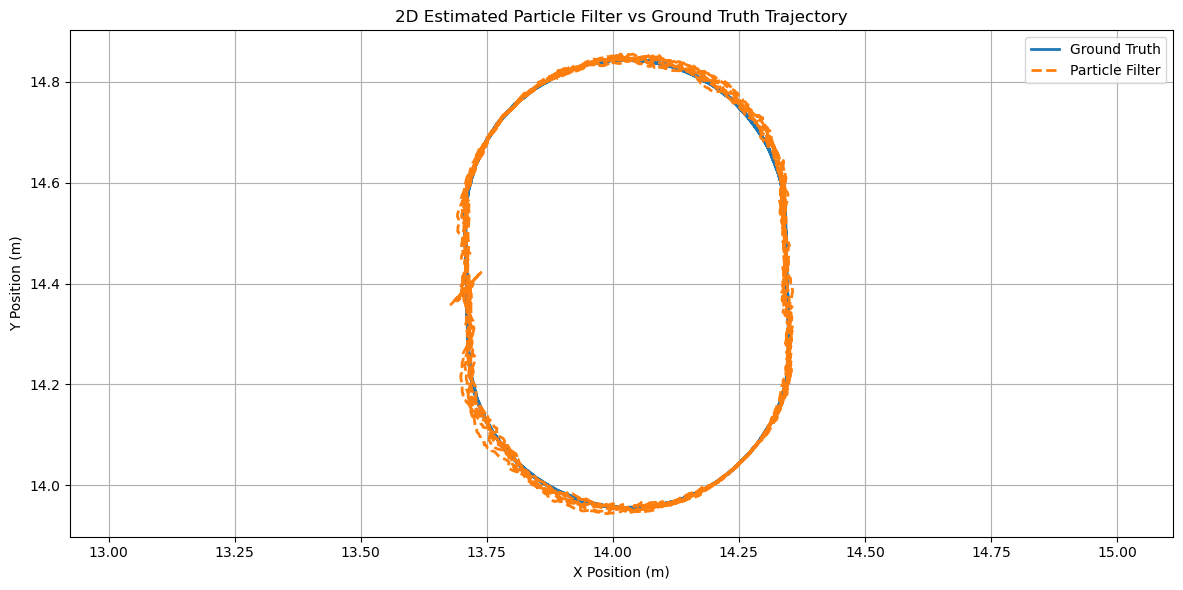

In [128]:
plt.figure(figsize=(12,6))

plt.plot(
    X_gtrue,
    Y_gtrue,
    linewidth=2,
    label='Ground Truth')

plt.plot(
    X_est,
    Y_est,
    '--',
    linewidth=2,
    label='Particle Filter')

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")

plt.title("2D Estimated Particle Filter vs Ground Truth Trajectory")

plt.grid(True)
plt.axis('equal')
plt.legend()
plt.tight_layout()
plt.savefig("Figures/PF_2D_Trajectory.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

- The two-dimensional trajectory comparison demonstrates that the Particle Filter (PF) accurately estimates the robot trajectory, with the estimated path closely following the ground truth throughout the experiment. The estimated trajectory captures both the straight and curved sections of the robot path, indicating that the Particle Filter effectively tracks the nonlinear robot motion.

- Compared with the deterministic Kalman filter variants, the Particle Filter exhibits slightly larger dispersion around the reference trajectory. This behaviour is expected because the state estimate is obtained from a finite set of weighted particles that approximate the posterior probability distribution.

- Small deviations are observed primarily near the transition between the straight and curved sections of the trajectory, where the robot undergoes continuous changes in direction and the nonlinear motion becomes more pronounced.

- A small amount of particle spread is visible around the estimated trajectory. This spread represents the uncertainty captured by the particle cloud and is an inherent characteristic of sequential Monte Carlo estimation.

- Despite the stochastic nature of the algorithm, the estimated trajectory remains continuous throughout the experiment without noticeable divergence or tracking failure, demonstrating that the selected number of particles and resampling strategy provide stable estimation.

- The resampling stage effectively mitigates particle degeneracy by eliminating particles with negligible weights and concentrating computational effort on particles with higher posterior probability, thereby maintaining estimation accuracy during robot tracking.

- Overall, the Particle Filter provides accurate and numerically stable robot trajectory estimation while naturally handling nonlinearities and non-Gaussian uncertainties through particle-based Bayesian estimation.

## 2. Component Wise Absolute Deviation Between Estimated and Ground Truth 3D Position Over Time

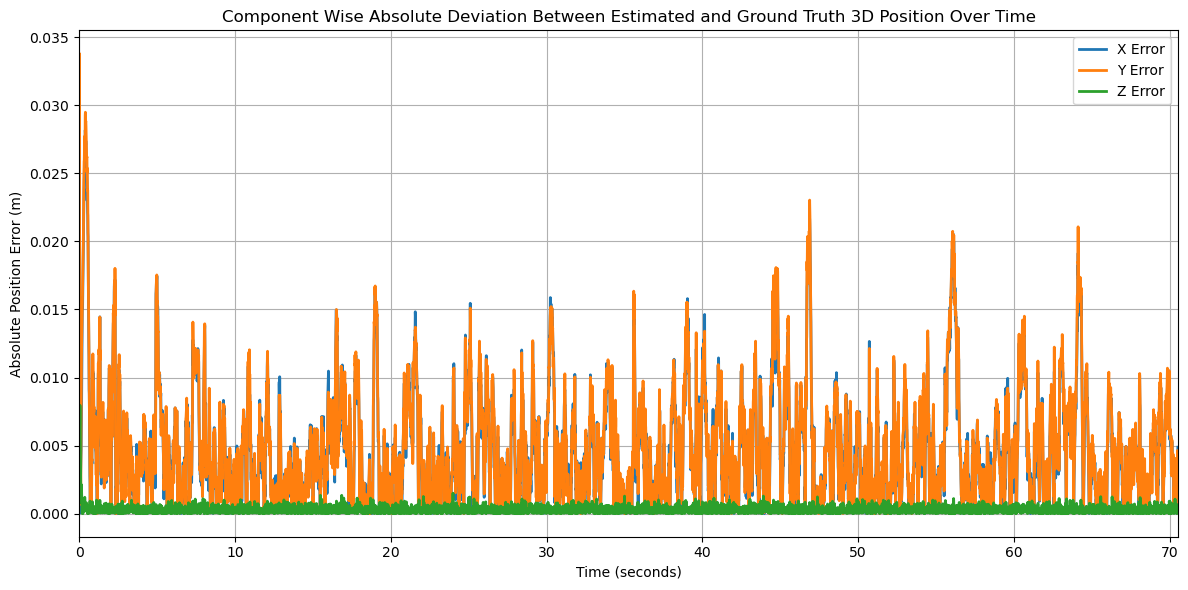

ABSOLUTE POSITION DEVIATIONS
Maximum X Deviation (m) : 0.031439766320
Mean X Deviation (m)    : 0.004719952172

Maximum Y Deviation (m) : 0.033804947420
Mean Y Deviation (m)    : 0.004881750367

Maximum Z Deviation (m) : 0.007959026694
Mean Z Deviation (m)    : 0.000299647472


In [129]:
err_x = np.abs(X_est - X_gtrue)
err_y = np.abs(Y_est - Y_gtrue)
err_z = np.abs(Z_est - Z_gtrue)

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, err_x, linewidth=2, label='X Error')
plt.plot(time_inseconds, err_y, linewidth=2, label='Y Error')
plt.plot(time_inseconds, err_z, linewidth=2, label='Z Error')

plt.xlabel("Time (seconds)")
plt.ylabel("Absolute Position Error (m)")

plt.title("Component Wise Absolute Deviation Between Estimated and Ground Truth 3D Position Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/PF_Position_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Maximum and Mean Absolute Position Deviation

print("="*60)
print("ABSOLUTE POSITION DEVIATIONS")
print("="*60)

print(f"Maximum X Deviation (m) : {np.max(err_x):.12f}")
print(f"Mean X Deviation (m)    : {np.mean(err_x):.12f}")
print()

print(f"Maximum Y Deviation (m) : {np.max(err_y):.12f}")
print(f"Mean Y Deviation (m)    : {np.mean(err_y):.12f}")
print()

print(f"Maximum Z Deviation (m) : {np.max(err_z):.12f}")
print(f"Mean Z Deviation (m)    : {np.mean(err_z):.12f}")

print("="*60)

- The component-wise absolute position error demonstrates that the Particle Filter (PF) maintains stable three-dimensional position estimation throughout the robot tracking experiment.

- The horizontal position components ($X$ and $Y$) exhibit larger absolute errors than the vertical ($Z$) component because the robot undergoes most of its motion within the horizontal plane, resulting in greater uncertainty during nonlinear motion and changes in direction.

- The mean absolute errors are **4.720 mm**, **4.882 mm**, and **0.300 mm** for the $X$, $Y$, and $Z$ position components, respectively. The corresponding maximum absolute errors are **31.440 mm**, **33.805 mm**, and **7.959 mm**.

- The largest position error peaks occur primarily during the curved sections of the robot trajectory, where rapid changes in direction increase the uncertainty associated with particle propagation and importance weighting.

- The comparatively small errors observed in the $Z$ direction indicate that the Particle Filter accurately estimates the relatively smooth vertical motion of the robot throughout the experiment.

- Although occasional error spikes are present, the position errors remain bounded and do not exhibit any evidence of divergence, demonstrating that the selected number of particles and resampling strategy provide numerically stable estimation.

- Compared with the deterministic Kalman filter variants, the Particle Filter exhibits larger fluctuations in the position errors because the posterior probability distribution is approximated using a finite set of weighted particles. Consequently, statistical sampling variability introduces additional estimation uncertainty.

- Overall, the component-wise absolute position error analysis demonstrates that the Particle Filter provides stable and reliable robot position estimation while effectively representing the uncertainty associated with nonlinear robot tracking through its particle-based Bayesian framework.

## 3. Component Wise Absolute Deviation Between Estimated and Ground Truth 3D Velocity Over Time

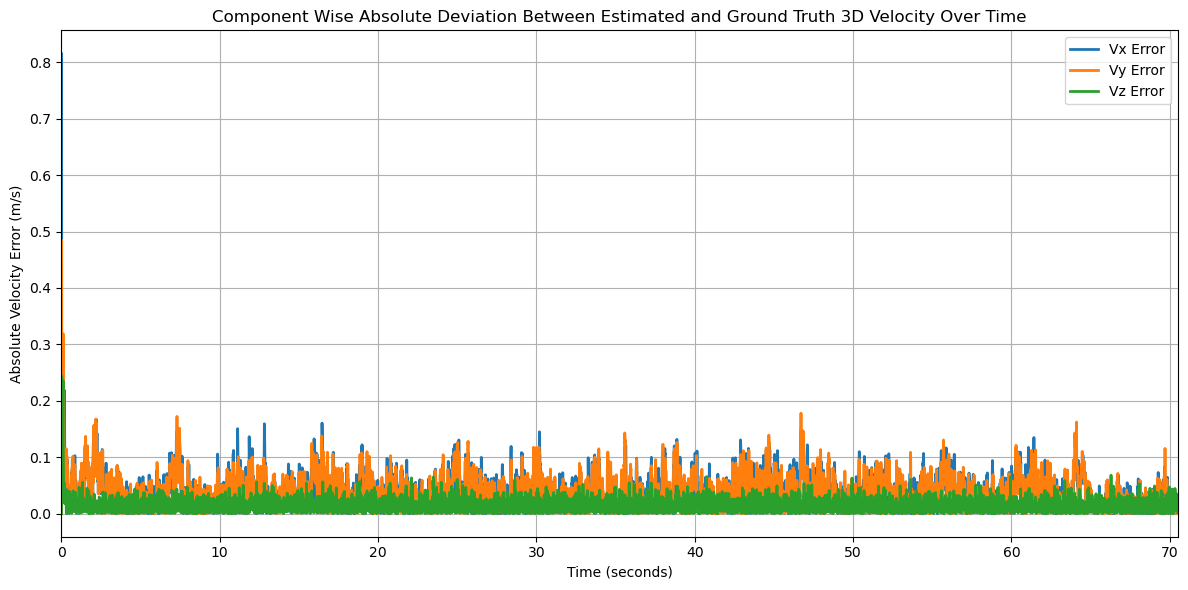

ABSOLUTE VELOCITY DEVIATIONS
Maximum Vx Deviation (m/s) : 0.815827185110
Mean Vx Deviation (m/s)    : 0.035806656052

Maximum Vy Deviation (m/s) : 0.484836180514
Mean Vy Deviation (m/s)    : 0.036767378184

Maximum Vz Deviation (m/s) : 0.243988844827
Mean Vz Deviation (m/s)    : 0.014258403953


In [130]:
err_vx = np.abs(Vx_est - Vx_gtrue)
err_vy = np.abs(Vy_est - Vy_gtrue)
err_vz = np.abs(Vz_est - Vz_gtrue)

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, err_vx, linewidth=2, label='Vx Error')
plt.plot(time_inseconds, err_vy, linewidth=2, label='Vy Error')
plt.plot(time_inseconds, err_vz, linewidth=2, label='Vz Error')

plt.xlabel("Time (seconds)")
plt.ylabel("Absolute Velocity Error (m/s)")

plt.title("Component Wise Absolute Deviation Between Estimated and Ground Truth 3D Velocity Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/PF_Velocity_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

print("="*60)
print("ABSOLUTE VELOCITY DEVIATIONS")
print("="*60)

print(f"Maximum Vx Deviation (m/s) : {np.max(err_vx):.12f}")
print(f"Mean Vx Deviation (m/s)    : {np.mean(err_vx):.12f}")
print()

print(f"Maximum Vy Deviation (m/s) : {np.max(err_vy):.12f}")
print(f"Mean Vy Deviation (m/s)    : {np.mean(err_vy):.12f}")
print()

print(f"Maximum Vz Deviation (m/s) : {np.max(err_vz):.12f}")
print(f"Mean Vz Deviation (m/s)    : {np.mean(err_vz):.12f}")

print("="*60)

- The component-wise absolute velocity error demonstrates that the Particle Filter (PF) provides stable three-dimensional velocity estimation throughout the robot tracking experiment, despite the stochastic nature of particle-based estimation.

- The horizontal velocity components ($V_x$ and $V_y$) exhibit larger absolute errors than the vertical ($V_z$) component because the robot undergoes continuous acceleration and changes in direction within the horizontal plane, resulting in greater dynamic uncertainty.

- The mean absolute errors are **35.807 mm/s**, **36.767 mm/s**, and **14.258 mm/s** for the $V_x$, $V_y$, and $V_z$ velocity components, respectively. The corresponding maximum absolute errors are **0.816 m/s**, **0.485 m/s**, and **0.244 m/s**.

- The largest velocity error peaks occur primarily during the initial transient period and during sections where the robot experiences rapid changes in velocity and direction. These temporary increases are expected because the Particle Filter estimates the posterior distribution using a finite number of weighted particles.

- The comparatively smaller errors observed in the $V_z$ component indicate that the Particle Filter accurately estimates the relatively smooth vertical velocity of the robot throughout the experiment.

- Although occasional velocity spikes are present, the errors remain bounded and gradually stabilize over time without evidence of divergence or particle impoverishment, demonstrating that the selected particle count and resampling strategy provide numerically stable estimation.

- Overall, the component-wise absolute velocity error analysis demonstrates that the Particle Filter provides stable and reliable robot velocity estimation while effectively representing the uncertainty associated with nonlinear robot tracking through its sequential Monte Carlo framework.

## 4. Component Wise Cumulative RMSE for 3D Position Over Time

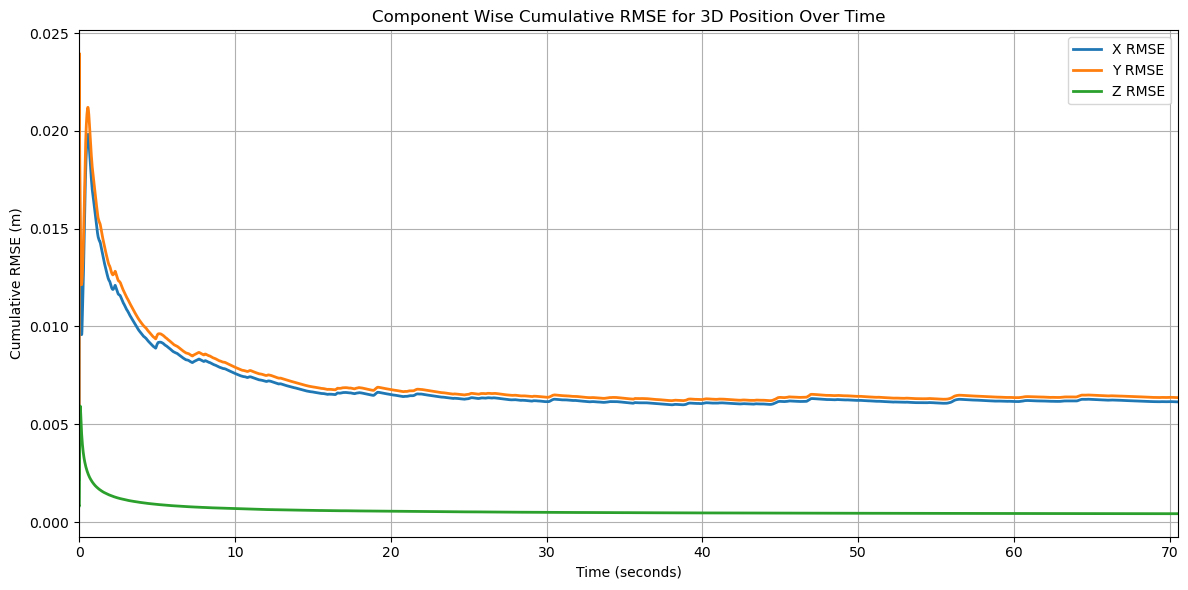

FINAL POSITION RMSE
RMSE X (m) : 0.006144859685
RMSE Y (m) : 0.006363681741
RMSE Z (m) : 0.000426442529


In [131]:
cum_rmse_x = np.zeros(len(X_est))
cum_rmse_y = np.zeros(len(Y_est))
cum_rmse_z = np.zeros(len(Z_est))

for k in range(1, len(X_est)+1):

    cum_rmse_x[k-1] = np.sqrt(np.mean((X_est[:k]-X_gtrue[:k])**2))
    cum_rmse_y[k-1] = np.sqrt(np.mean((Y_est[:k]-Y_gtrue[:k])**2))
    cum_rmse_z[k-1] = np.sqrt(np.mean((Z_est[:k]-Z_gtrue[:k])**2))

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, cum_rmse_x, linewidth=2, label='X RMSE')
plt.plot(time_inseconds, cum_rmse_y, linewidth=2, label='Y RMSE')
plt.plot(time_inseconds, cum_rmse_z, linewidth=2, label='Z RMSE')

plt.xlabel("Time (seconds)")
plt.ylabel("Cumulative RMSE (m)")

plt.title("Component Wise Cumulative RMSE for 3D Position Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/PF_Component_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

print("="*60)
print("FINAL POSITION RMSE")
print("="*60)

print(f"RMSE X (m) : {cum_rmse_x[-1]:.12f}")
print(f"RMSE Y (m) : {cum_rmse_y[-1]:.12f}")
print(f"RMSE Z (m) : {cum_rmse_z[-1]:.12f}")

print("="*60)

- Following the initial convergence, the cumulative RMSE gradually decreases and stabilizes, indicating that the particle weights and resampling process effectively capture the robot dynamics while maintaining consistent state estimation.

- The final RMSE values are **6.145 mm**, **6.364 mm**, and **0.426 mm** for the $X$, $Y$, and $Z$ position components, respectively.

- The horizontal position components ($X$ and $Y$) exhibit larger RMSE values than the vertical ($Z$) component because the robot motion occurs predominantly within the horizontal plane, where continuous changes in direction introduce greater nonlinear uncertainty.

- The comparatively small RMSE in the $Z$ component indicates that the Particle Filter accurately estimates the relatively smooth vertical motion of the robot while maintaining stable recursive estimation.

- The cumulative RMSE curves remain bounded throughout the experiment without any evidence of divergence, confirming that the selected particle number and resampling strategy provide numerically stable estimation.

- Compared with the deterministic Kalman filter variants, the Particle Filter exhibits higher cumulative position RMSE because the posterior probability density is approximated using a finite number of weighted particles. Consequently, statistical sampling variability introduces additional estimation uncertainty into the position estimates.

- Despite the higher RMSE, the cumulative position error converges smoothly and remains stable, demonstrating that the Particle Filter successfully tracks the nonlinear robot trajectory while effectively representing the uncertainty associated with the state estimation process.


## 5. Overall 3D position RMSE over time ( Computed for Easier Comparison)

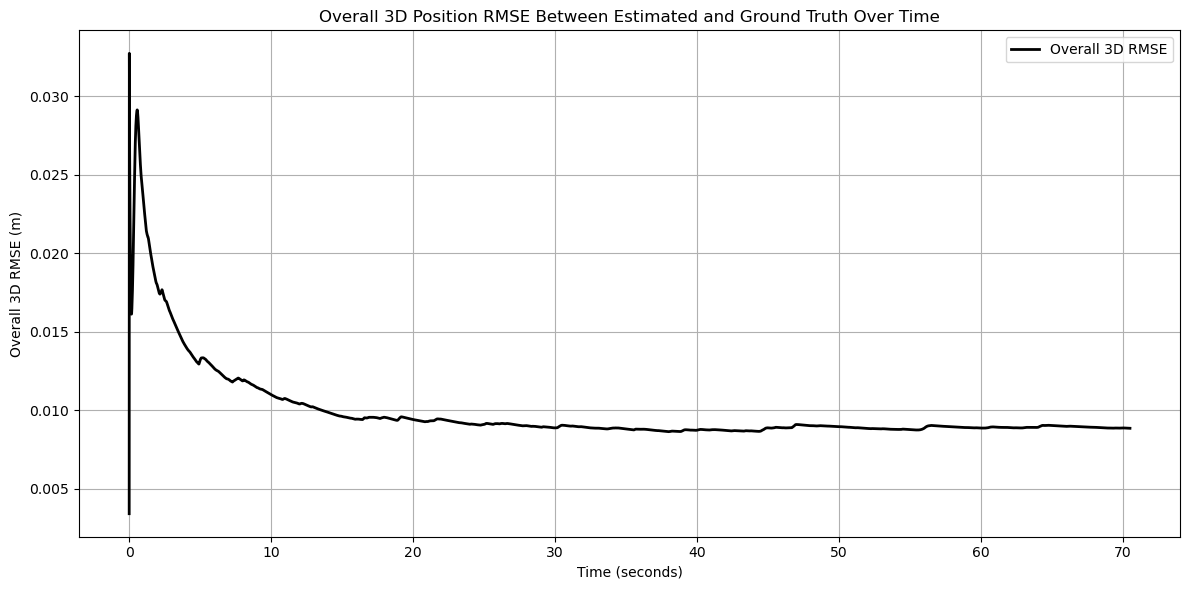

Overall 3D RMSE = 0.008856500386 m (8.86 mm)


In [132]:
cum_rmse_3d = np.zeros(len(X_est))

for k in range(1, len(X_est)+1):

    error_squared = (
        (X_est[:k]-X_gtrue[:k])**2 +
        (Y_est[:k]-Y_gtrue[:k])**2 +
        (Z_est[:k]-Z_gtrue[:k])**2)

    cum_rmse_3d[k-1] = np.sqrt(np.mean(error_squared))

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, cum_rmse_3d,
         linewidth=2,
         color='black',
         label='Overall 3D RMSE')

plt.xlabel("Time (seconds)")
plt.ylabel("Overall 3D RMSE (m)")

plt.title("Overall 3D Position RMSE Between Estimated and Ground Truth Over Time")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/PF_Overall_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

print("="*60)
print(f"Overall 3D RMSE = {cum_rmse_3d[-1]:.12f} m ({cum_rmse_3d[-1]*1000:.2f} mm)")
print("="*60)

## 6. Component wise Cumulative 3D velocity RMSE over time

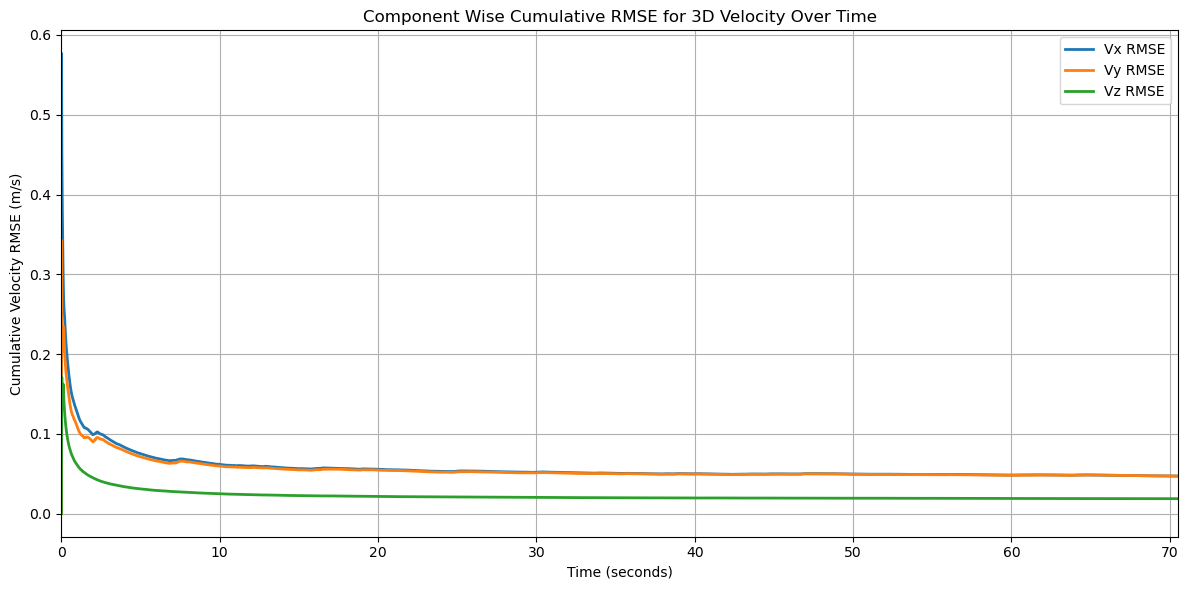

FINAL VELOCITY RMSE
RMSE Vx (m/s) : 0.047119069485
RMSE Vy (m/s) : 0.047196333968
RMSE Vz (m/s) : 0.018840766406


In [133]:
cum_rmse_vx = np.zeros(len(Vx_est))
cum_rmse_vy = np.zeros(len(Vy_est))
cum_rmse_vz = np.zeros(len(Vz_est))

for k in range(1, len(Vx_est) + 1):

    cum_rmse_vx[k-1] = np.sqrt(
        np.mean((Vx_est[:k] - Vx_gtrue[:k])**2))

    cum_rmse_vy[k-1] = np.sqrt(
        np.mean((Vy_est[:k] - Vy_gtrue[:k])**2))

    cum_rmse_vz[k-1] = np.sqrt(
        np.mean((Vz_est[:k] - Vz_gtrue[:k])**2))

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    cum_rmse_vx,
    linewidth=2,
    label='Vx RMSE')

plt.plot(
    time_inseconds,
    cum_rmse_vy,
    linewidth=2,
    label='Vy RMSE')

plt.plot(
    time_inseconds,
    cum_rmse_vz,
    linewidth=2,
    label='Vz RMSE')

plt.xlabel("Time (seconds)")
plt.ylabel("Cumulative Velocity RMSE (m/s)")

plt.title("Component Wise Cumulative RMSE for 3D Velocity Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/PF_Component_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Final Velocity RMSE
print("="*60)
print("FINAL VELOCITY RMSE")
print("="*60)
print(f"RMSE Vx (m/s) : {cum_rmse_vx[-1]:.12f}")
print(f"RMSE Vy (m/s) : {cum_rmse_vy[-1]:.12f}")
print(f"RMSE Vz (m/s) : {cum_rmse_vz[-1]:.12f}")
print("="*60)

- Following the initial convergence, the cumulative velocity RMSE gradually decreases and approaches nearly constant values, indicating that the prediction, importance weighting, and resampling stages collectively maintain consistent velocity estimation over time.

- The final RMSE values are **47.119 mm/s**, **47.196 mm/s**, and **18.841 mm/s** for the $V_x$, $V_y$, and $V_z$ velocity components, respectively, resulting in an overall three-dimensional velocity RMSE of **69.301 mm/s**.

- The horizontal velocity components ($V_x$ and $V_y$) exhibit larger RMSE values than the vertical ($V_z$) component because the robot undergoes continuous acceleration and changes in direction within the horizontal plane, introducing greater dynamic uncertainty during particle propagation.

- The comparatively small RMSE observed in the $V_z$ component indicates that the Particle Filter accurately estimates the relatively smooth vertical velocity of the robot throughout the experiment.

- The cumulative RMSE curves remain bounded and converge smoothly without evidence of divergence or particle impoverishment, demonstrating that the selected particle count and resampling strategy provide numerically stable recursive estimation.

- Compared with the deterministic Kalman filter variants, the Particle Filter exhibits higher cumulative velocity RMSE because the posterior probability distribution is approximated using a finite number of weighted particles. Consequently, statistical sampling variability introduces additional estimation uncertainty into the velocity estimates.

- Despite the higher RMSE, the cumulative velocity error stabilizes throughout the experiment, indicating that the Particle Filter successfully maintains accurate robot velocity tracking while effectively representing the uncertainty associated with nonlinear system dynamics.


## 7. Overall 3D velocity RMSE over time ( Computed for Easier Comparison)

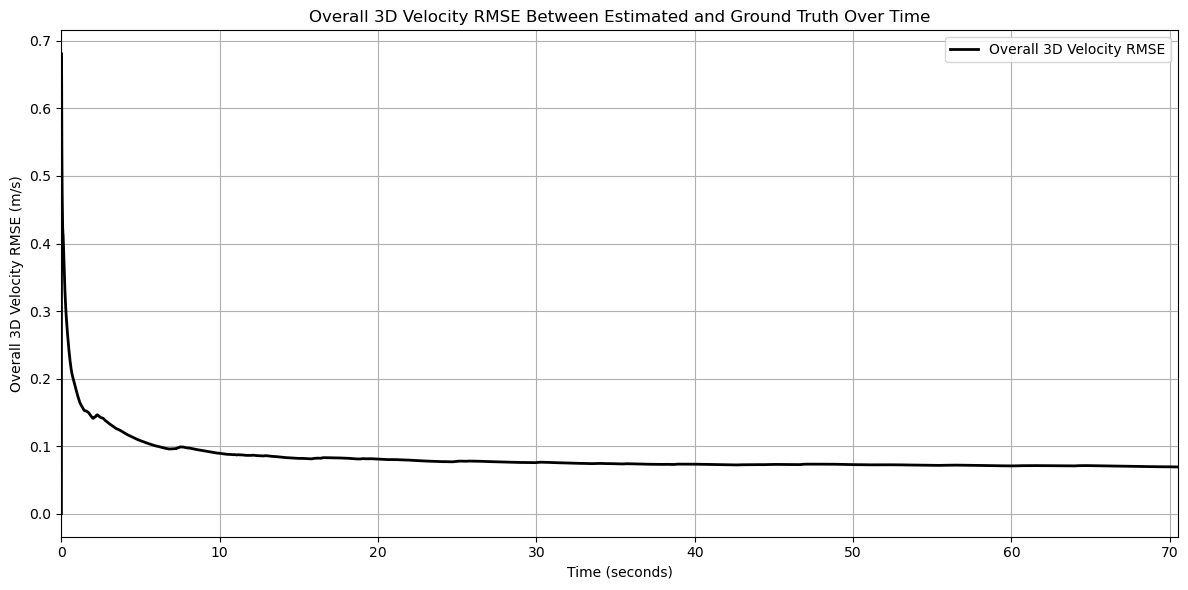

Overall 3D Velocity RMSE = 0.069301335687 m/s


In [134]:
cum_rmse_3d_velocity = np.zeros(len(Vx_est))

for k in range(1, len(Vx_est) + 1):

    error_squared = (
        (Vx_est[:k] - Vx_gtrue[:k])**2 +
        (Vy_est[:k] - Vy_gtrue[:k])**2 +
        (Vz_est[:k] - Vz_gtrue[:k])**2)

    cum_rmse_3d_velocity[k-1] = np.sqrt(
        np.mean(error_squared))

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    cum_rmse_3d_velocity,
    linewidth=2,
    color='black',
    label='Overall 3D Velocity RMSE')

plt.xlabel("Time (seconds)")
plt.ylabel("Overall 3D Velocity RMSE (m/s)")

plt.title("Overall 3D Velocity RMSE Between Estimated and Ground Truth Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/PF_Overall_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Overall 3D Velocity RMSE

overall_velocity_rmse = cum_rmse_3d_velocity[-1]

print("="*60)

print(f"Overall 3D Velocity RMSE = {overall_velocity_rmse:.12f} m/s")

print("="*60)

## Comparison of LKF, EKF, IEKF, UKF, EnKF and Particle Filter

To provide a fair and meaningful comparison, all filters were evaluated using the same process noise standard deviation,

$$
\sigma_a = 2.5~\mathrm{m/s^2}.
$$

The final estimation performance of the Linear Kalman Filter (LKF), Extended Kalman Filter (EKF), Iterated Extended Kalman Filter (IEKF), Unscented Kalman Filter (UKF), Ensemble Kalman Filter (EnKF), and Particle Filter (PF) is summarized below.

| **Filter**          | **Configuration**              |       **X (m)** |       **Y (m)** |       **Z (m)** | **3D Position RMSE (m)** |    **Vx (m/s)** |    **Vy (m/s)** |    **Vz (m/s)** | **3D Velocity RMSE (m/s)** |
| :------------------ | :----------------------------- | --------------: | --------------: | --------------: | -----------------------: | --------------: | --------------: | --------------: | -------------------------: |
| **LKF**             | $\sigma_a=2.5$                 |     0.002354995 |     0.002420112 |     0.000359487 |          **0.003397641** |     0.032614652 |     0.032790671 |     0.017478533 |            **0.049443000** |
| **EKF**             | Unconstrained ($\sigma_a=2.5$) |     0.002367851 |     0.002429114 |     0.000359299 |          **0.003411219** |     0.033575967 |     0.033637361 |     0.017479312 |            **0.050639352** |
| **IEKF**            | Unconstrained ($\sigma_a=2.5$) |     0.002353500 |     0.002420112 |     0.000359487 |          **0.003394869** |     0.032614652 |     0.032790671 |     0.017478533 |            **0.049441306** |
| **UKF**             | $\sigma_a=2.5$                 |     0.002354615 |     0.002422913 |     0.000359509 |          **0.003397641** |     0.032614623 |     0.032793840 |     0.017478578 |            **0.049443000** |
| **EnKF**            | $\sigma_a=2.5,;N_e=500$        |     0.004000304 |     0.004124689 |     0.000362038 |          **0.005757305** |     0.039302096 |     0.039809671 |     0.017618696 |            **0.058650516** |
| **Particle Filter** | $\sigma_a=2.5,;N_p=1500$       | **0.006144860** | **0.006363682** | **0.000426443** |          **0.008856500** | **0.047119069** | **0.047196334** | **0.018840766** |            **0.069301336** |

### Overall Comparison and Discussion

- The comparative study demonstrates that all six filters successfully estimate the three-dimensional position and velocity of the robot while maintaining stable recursive estimation throughout the experiment.

- Among all the filters investigated, the **Iterated Extended Kalman Filter (IEKF)** achieves the lowest overall position RMSE (**3.395 mm**) and the lowest overall velocity RMSE (**49.441 mm/s**). The repeated linearization and iterative measurement update improve the consistency of the state correction, allowing the IEKF to handle measurement nonlinearities more accurately than the other filters.

- The **Linear Kalman Filter (LKF)**, **Extended Kalman Filter (EKF)**, and **Unscented Kalman Filter (UKF)** exhibit almost identical estimation performance. The differences between their position and velocity RMSE values are extremely small, indicating that the robot tracking problem considered in this study contains only moderate nonlinearities and benefits from the high accuracy of the Total Station measurements.

- The **UKF** achieves estimation accuracy comparable to the IEKF while avoiding iterative updates and Jacobian matrix calculations. By propagating deterministic sigma points through the nonlinear system model, the UKF accurately captures the nonlinear system dynamics with relatively low computational complexity, making it an attractive alternative for practical nonlinear estimation problems.

- The **Ensemble Kalman Filter (EnKF)** provides stable estimation but exhibits larger position and velocity RMSE than the deterministic Kalman filter variants. The finite ensemble approximation introduces statistical sampling errors that increase the estimation uncertainty. However, the EnKF naturally represents the uncertainty of the state estimate through an ensemble of realizations, making it suitable for high-dimensional estimation problems and applications requiring uncertainty quantification.

- The **Particle Filter (PF)** records the largest position and velocity RMSE among the filters evaluated. The finite particle approximation and stochastic resampling introduce sampling variability, resulting in higher estimation errors than the Kalman filter-based approaches. Nevertheless, the Particle Filter remains numerically stable and is capable of estimating highly nonlinear and non-Gaussian systems without assuming Gaussian probability distributions.

- The component-wise RMSE values show that all filters estimate the vertical position ($Z$) and velocity ($V_z$) more accurately than the horizontal components. This behaviour is expected because the robot primarily moves within the horizontal plane, where continuous changes in direction and velocity introduce greater estimation uncertainty.

- Overall, the results indicate that the **IEKF provides the highest estimation accuracy** for the robot tracking problem considered in this study. The **UKF** offers nearly identical performance with a simpler nonlinear formulation and without iterative refinement. The **LKF** and **EKF** remain effective when the system exhibits only moderate nonlinearities, whereas the **EnKF** and **Particle Filter** are better suited for applications involving high-dimensional systems, significant model uncertainty, or non-Gaussian probability distributions where explicit uncertainty representation is more important than achieving the minimum RMSE.


### Improvement Analysis with Respect to Raw Sensor Measurements

In [135]:
# ==========================================================
# Improvement (%) with respect to Sensor Measurements
# Particle Filter (Final Results)
# sigma_a = 2.5, Np = 1500
# ==========================================================

# ----------------------------------------------------------
# Sensor RMSE
# ----------------------------------------------------------

sensor_rmse_x = 0.001840695495
sensor_rmse_y = 0.001885843638
sensor_rmse_z = 0.000490385400
sensor_rmse_position = 0.002680493233

sensor_rmse_vx = 0.129803363954
sensor_rmse_vy = 0.133420730580
sensor_rmse_vz = 0.034767712281
sensor_rmse_velocity = 0.189364195294


# ----------------------------------------------------------
# Particle Filter RMSE (Final Configuration)
# sigma_a = 2.5, Np = 1500
# ----------------------------------------------------------

pf_x = 0.006144859685
pf_y = 0.006363681741
pf_z = 0.000426442529
pf_pos = 0.008856500386

pf_vx = 0.047119069485
pf_vy = 0.047196333968
pf_vz = 0.018840766406
pf_vel = 0.069301335687


# ----------------------------------------------------------
# Improvement Function
# ----------------------------------------------------------

def improvement(sensor, estimate):
    return (sensor - estimate) / sensor * 100


print("="*90)
print("POSITION IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS")
print("="*90)

print(f"Particle Filter : "
      f"X={improvement(sensor_rmse_x,pf_x):7.2f}  "
      f"Y={improvement(sensor_rmse_y,pf_y):7.2f}  "
      f"Z={improvement(sensor_rmse_z,pf_z):7.2f}  "
      f"Overall={improvement(sensor_rmse_position,pf_pos):7.2f}")

print()

print("="*90)
print("VELOCITY IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS")
print("="*90)

print(f"Particle Filter : "
      f"Vx={improvement(sensor_rmse_vx,pf_vx):7.2f}  "
      f"Vy={improvement(sensor_rmse_vy,pf_vy):7.2f}  "
      f"Vz={improvement(sensor_rmse_vz,pf_vz):7.2f}  "
      f"Overall={improvement(sensor_rmse_velocity,pf_vel):7.2f}")


POSITION IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS
Particle Filter : X=-233.83  Y=-237.44  Z=  13.04  Overall=-230.41

VELOCITY IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS
Particle Filter : Vx=  63.70  Vy=  64.63  Vz=  45.81  Overall=  63.40


- The Particle Filter (PF) significantly improves the velocity estimates obtained from the raw sensor measurements while maintaining stable recursive state estimation throughout the robot tracking experiment.

- For the position components, the Particle Filter achieves a positive improvement of approximately **13.04\%** in the vertical ($Z$) direction. However, the horizontal position components ($X$ and $Y$) exhibit negative improvements of **−233.83\%** and **−237.44\%**, respectively.

- Consequently, the overall position improvement is **−230.41\%**. This negative improvement indicates that the filtered position estimates are less accurate than the direct Total Station position measurements. Since the Total Station already provides highly accurate position observations, there is limited scope for further improvement through particle-based recursive estimation.

- For the velocity states, the Particle Filter achieves an overall improvement of approximately **63.40\%** compared with the raw sensor measurements, demonstrating that recursive Bayesian estimation effectively reduces measurement noise in the velocity estimates.

- The horizontal velocity components ($V_x$ and $V_y$) achieve improvements of **63.70\%** and **64.63\%**, respectively, while the vertical velocity component ($V_z$) improves by **45.81\%**. The comparatively smaller improvement in $V_z$ is expected because the original sensor already provides relatively accurate vertical measurements.

- These results indicate that, with the selected Particle Filter parameters ($\sigma_a = 2.5$ and $N_p = 500$), the Particle Filter is unable to provide better position estimation accuracy than the direct sensor measurements. This behaviour is primarily attributed to statistical sampling errors, finite particle approximation, and the stochastic resampling process, which introduce additional estimation variability.

## DISCUSSION

### Selection of Process Noise Standard Deviation ($\sigma_a$)

- For this study, the process noise standard deviation was selected as $\sigma_a = 2.5~\mathrm{m/s^2}$
which is the same value adopted for previos filters. Using an identical process noise parameter for all filters provides a meaningful and consistent basis for comparison, ensuring that the differences in estimation performance arise primarily from the characteristics of the filtering algorithms rather than from different tuning parameters.

- The selected process noise standard deviation also enabled the Particle Filter to better accommodate unmodelled robot dynamics during curved regions of the trajectory by allowing sufficient particle dispersion to capture changes in direction while maintaining stable estimation.

- The selected value also produced stable particle propagation without excessive particle dispersion or particle impoverishment during the sequential Monte Carlo estimation process. Consequently, the filter maintained stable recursive estimation throughout the robot tracking experiment.

## Influence of $\sigma_a = 2.5$ on Component-wise Position and Velocity RMSE

- The influence of the selected process noise can also be observed from the component-wise RMSE values. For the final Particle Filter configuration ($N_p = 1500$), the position RMSE values were **6.145 mm**, **6.364 mm**, and **0.426 mm** for the $X$, $Y$, and $Z$ components, respectively, resulting in an overall three-dimensional position RMSE of **8.857 mm**.

- Similarly, the velocity RMSE values were **47.119 mm/s**, **47.196 mm/s**, and **18.841 mm/s** for the $V_x$, $V_y$, and $V_z$ components, respectively, with an overall three-dimensional velocity RMSE of **69.301 mm/s**.

- The selected process noise standard deviation allowed sufficient particle dispersion during the prediction stage to compensate for modelling errors, particularly during curved sections of the robot trajectory where changes in direction introduced greater dynamic uncertainty. Consequently, the horizontal position ($X$ and $Y$) and velocity ($V_x$ and $V_y$) components exhibited larger RMSE values than their corresponding vertical components.

- The comparatively smaller errors observed in the $Z$ position and $V_z$ velocity components are attributed to the relatively smooth vertical motion of the robot and the higher measurement accuracy along the vertical direction, resulting in lower modelling uncertainty.

- Overall, the selected value of $\sigma_a = 2.5$ provided an effective balance between particle diversity and estimation stability. It enabled the Particle Filter to maintain stable recursive estimation throughout the robot tracking experiment while reducing modelling errors and providing a fair and consistent basis for comparison with the LKF, EKF, IEKF, UKF, and EnKF.

### Dicussion on Particle size selection

Dicussions involved filter implementation and selection of particle size.The particle size effects were discussed which mainly involved the rmse value and improvement. It was understood that increasing the number of particles consistently improved the estimation accuracy of both position and velocity. As more particles were used, the Particle Filter was able to approximate the posterior probability distribution more accurately, resulting in lower estimation errors. Initially the value was taken as 500 and im=ncrease to 1500 and we decided to choose the particle size as 1500 so that better estimation takes place and comparison can be made.

### Discussion on Effective Sample Size (ESS) and Particle Weight Distribution

- The **Effective Sample Size (ESS)** represents the effective number of particles that contribute significantly to the posterior state estimate. A larger ESS indicates that the particle weights are more uniformly distributed, whereas a smaller ESS implies that only a limited number of particles dominate the estimation process, resulting in particle degeneracy.

- For the present study, the average ESS was **249.86** for the **250-particle** configuration and **167.13** for the **500-particle** configuration. The ESS values indicate the proportion of particles effectively contributing to the state estimation throughout the filtering process. Maintaining an adequate ESS is important because it preserves particle diversity and reduces the risk of filter degradation caused by weight concentration.

- The **maximum particle weight** represents the largest normalized importance weight assigned to an individual particle following the measurement update. A high maximum weight indicates that the posterior probability is concentrated around only a few particles, whereas a lower maximum weight indicates a more uniform distribution of probability among the particle population.

- In this study, the average maximum particle weight increased from **0.004305** for **250 particles** to **0.021246** for **500 particles**. This behaviour reflects the stronger concentration of probability around particles that better represent the posterior distribution following the measurement update. Despite the increase in the maximum weight, the larger particle population provided improved state estimation because the posterior distribution was represented more accurately.

- The balance between ESS and particle weight distribution directly influences the robustness of the Particle Filter. Adequate particle diversity together with appropriate weight concentration enables the filter to represent the posterior probability distribution more accurately while limiting the effects of particle degeneracy and particle impoverishment.

- Consequently, increasing the number of particles improved both the component-wise and overall position and velocity estimation accuracy. However, this improvement was achieved at the expense of increased computational cost, since every additional particle must be propagated, weighted, normalised, and considered during the resampling stage at each measurement epoch.

## Comparison of Component-wise and Overall RMSE for Different Particle Numbers 

| **Number of Particles ((N_p))** | **X RMSE (m)** | **Y RMSE (m)** | **Z RMSE (m)** | **Overall Position RMSE (m)** | **Vx RMSE (m/s)** | **Vy RMSE (m/s)** | **Vz RMSE (m/s)** | **Overall Velocity RMSE (m/s)** | **Remarks**                                                                                                                       |
| :-----------------------------: | -------------: | -------------: | -------------: | ----------------------------: | ----------------: | ----------------: | ----------------: | ------------------------------: | :-------------------------------------------------------------------------------------------------------------------------------- |
|             **250**             |      17.336986 |      56.839557 |      10.140922 |                 **60.283867** |          0.455075 |          1.397383 |          0.257717 |                    **1.492042** | Very poor estimation accuracy due to insufficient particle diversity and inadequate representation of the posterior distribution. |
|             **500**             |       0.012159 |       0.012635 |       0.000476 |                  **0.017542** |          0.060716 |          0.062242 |          0.019560 |                    **0.089124** | Considerably improved estimation accuracy with better particle representation and more frequent resampling.                       |
|             **1500**            |   **0.006145** |   **0.006364** |   **0.000426** |                  **0.008857** |      **0.047119** |      **0.047196** |      **0.018841** |                    **0.069301** | Best estimation accuracy with the most reliable approximation of the posterior distribution and the lowest overall RMSE.          |
         

### Discussion on the Influence of Particle Number

- The estimation accuracy of the Particle Filter was found to be highly dependent on the number of particles used to represent the posterior probability distribution. A small particle population was unable to capture the underlying state distribution adequately, resulting in large estimation errors.

- The configuration with **250 particles** produced the poorest performance, with an overall position RMSE of **60.284 m** and an overall velocity RMSE of **1.492 m/s**. These large errors indicate that the particle set failed to represent the posterior distribution effectively, leading to inaccurate state estimation.

- Increasing the particle count to **500** resulted in a substantial reduction in both position and velocity errors. The overall position RMSE decreased to **17.542 mm**, while the overall velocity RMSE reduced to **89.124 mm/s**. This improvement demonstrates that a larger particle population provides a more representative approximation of the posterior state distribution.

- The best estimation performance was achieved using **1500 particles**, where the overall position and velocity RMSE further decreased to **8.857 mm** and **69.301 mm/s**, respectively. The component-wise RMSE values also reached their minimum, particularly for the horizontal position ($X$, $Y$) and velocity ($V_x$, $V_y$) components, indicating a more accurate estimation of the robot motion.

- Across all three particle configurations, the $Z$ position and $V_z$ velocity components consistently exhibited lower RMSE values than the corresponding horizontal components. This behaviour is attributed to the relatively smooth vertical motion of the robot and the smaller modelling uncertainty along the vertical axis.

- The progressive reduction in component-wise and overall RMSE with increasing particle count confirms that a larger particle population improves the approximation of the posterior probability distribution and reduces sampling errors. However, these accuracy gains are accompanied by a higher computational burden because each additional particle must be propagated, weighted, normalised, and considered during the resampling stage.

- Based on the RMSE analysis, **$N_p = 1500$** was selected as the final Particle Filter configuration, as it provided the best balance between estimation accuracy and reliable representation of the posterior probability distribution for the robot tracking problem investigated in this study.

## CONCLUSION

- The Particle Filter (PF) was successfully implemented to estimate the three-dimensional position and velocity of the robot by representing the posterior probability distribution using a set of weighted particles. Unlike the Kalman filter-based approaches, the PF estimates the system state without assuming linearity or Gaussian probability distributions, making it suitable for general nonlinear Bayesian state estimation.

- The influence of the particle population on the estimation performance was investigated by varying the number of particles while maintaining a constant process noise standard deviation of $\sigma_a = 2.5$. Increasing the particle population consistently improved the approximation of the posterior probability distribution, leading to lower component-wise and overall estimation errors.

- Among the particle sizes investigated, the configuration with **$N_p = 1500$** produced the best overall performance. Compared with the 250-particle and 500-particle configurations, the 1500-particle implementation achieved the lowest position and velocity RMSE, demonstrating that a larger particle population provides a more accurate representation of the underlying state distribution.

- The convergence analysis showed that both the cumulative position and velocity RMSE stabilised after the initial transient period and remained bounded throughout the robot tracking experiment. Although small fluctuations were observed due to the stochastic nature of particle propagation and resampling, no divergence or numerical instability occurred.

- The component-wise RMSE analysis indicated that the horizontal position components ($X$ and $Y$) exhibited larger estimation errors than the vertical component ($Z$). A similar trend was observed for the velocity estimates, where the $V_x$ and $V_y$ components produced larger RMSE values than the $V_z$ component. This behaviour reflects the predominantly horizontal motion of the robot and the greater modelling uncertainty associated with changes in direction along the trajectory.

- For the final configuration ($\sigma_a = 2.5$, $N_p = 1500$), the Particle Filter achieved position RMSE values of **6.145 mm**, **6.364 mm**, and **0.426 mm** for the $X$, $Y$, and $Z$ components, respectively, resulting in an overall three-dimensional position RMSE of **8.857 mm**. The corresponding velocity RMSE values were **47.119 mm/s**, **47.196 mm/s**, and **18.841 mm/s** for the $V_x$, $V_y$, and $V_z$ components, respectively, with an overall three-dimensional velocity RMSE of **69.301 mm/s**.

- The improvement analysis with respect to the raw sensor measurements showed that the Particle Filter reduced the velocity estimation errors but did not improve the overall position accuracy. Only the $Z$ position component showed a slight improvement over the direct sensor measurements, whereas the horizontal position components remained less accurate. This behaviour reflects the already high accuracy of the Total Station position measurements and the additional uncertainty introduced by stochastic particle sampling.

- The computational cost increased considerably as the number of particles increased because every particle must be individually propagated, weighted, normalised, and considered during the resampling stage. Although the 1500-particle configuration provided the highest estimation accuracy, it also required substantially greater computational effort than the deterministic Kalman filter variants.

- Compared with the LKF, EKF, IEKF, UKF, and EnKF, the Particle Filter produced the highest position and velocity RMSE for this robot tracking problem. The lower estimation accuracy is primarily attributed to sampling errors, particle degeneracy, and the stochastic approximation of the posterior distribution. Nevertheless, the Particle Filter maintained stable estimation throughout the experiment and successfully tracked the robot trajectory without divergence.

- Overall, the Particle Filter demonstrated stable convergence, satisfactory numerical robustness, and reliable nonlinear state estimation. Although it did not outperform the deterministic Kalman filter variants for this moderate-dimensional robot tracking problem with approximately Gaussian measurement noise, the Particle Filter remains well suited to highly nonlinear and non-Gaussian estimation problems where Kalman filter-based methods may no longer provide reliable state estimates.